### sprawdzenie czy jest okej ###

In [5]:
from pathlib import Path

import geopandas as gpd
import rasterio
import shapely

print("GeoPandas:", gpd.__version__)
print("Rasterio:", rasterio.__version__, "| GDAL:", rasterio.__gdal_version__)
print("Shapely:", shapely.__version__)

dane = Path("dane")
b04 = dane / "S2_L2A_2026-10-06_B04.tiff"
b08 = dane / "S2_L2A_2026-10-06_B08.tiff"

with rasterio.open(b04) as red, rasterio.open(b08) as nir:
    for nazwa, raster in [("B04", red), ("B08", nir)]:
        print(nazwa, "| rozmiar:", raster.shape, "| piksel:", raster.res,
              "| CRS:", raster.crs, "| liczba pasm:", raster.count)

    zgodne = (
        red.crs == nir.crs
        and red.shape == nir.shape
        and red.transform == nir.transform
    )
    print("Identyczna siatka obu rastrów:", zgodne)

GeoPandas: 1.2.0
Rasterio: 1.5.2 | GDAL: 3.12.2
Shapely: 2.2.0
B04 | rozmiar: (2500, 2138) | piksel: (0.00012628624883068268, 8.000000000000113e-05) | CRS: EPSG:4326 | liczba pasm: 1
B08 | rozmiar: (2500, 2138) | piksel: (0.00012628624883068268, 8.000000000000113e-05) | CRS: EPSG:4326 | liczba pasm: 1
Identyczna siatka obu rastrów: True


### część A1 ###

In [6]:
from shapely.geometry import Point, Polygon

rynek = Point(17.9226, 50.6681)
square = Polygon([
    (17.92, 50.66),
    (17.93, 50.66),
    (17.93, 50.67),
    (17.92, 50.67),
])

print("Rynek:", rynek)
print("Pole prostokąta:", square.area)
print("Czy Rynek leży wewnątrz?", square.contains(rynek))

Rynek: POINT (17.9226 50.6681)
Pole prostokąta: 0.00010000000000003127
Czy Rynek leży wewnątrz? True


In [3]:
import geopandas as gpd

places = gpd.GeoDataFrame(
    {"name": ["Rynek", "Prostokąt"]},
    geometry=[rynek, square],
    crs="EPSG:4326",
)

display(places)
print("Układ współrzędnych:", places.crs)
print("Typy geometrii:", places.geom_type.to_list())

,name,geometry
0,Rynek,POINT (17.9226 50.6681)
1,Prostokąt,"POLYGON ((17.92 50.66, 17.93 50.66, 17.93 50.6..."


Układ współrzędnych: EPSG:4326
Typy geometrii: ['Point', 'Polygon']


### część A2 ###

In [7]:
import pandas as pd

raw = pd.read_csv("dane/pm25_sensors.csv", parse_dates=["measured_at"])

print("Wiersze i kolumny:", raw.shape)
display(raw.head(10))

Wiersze i kolumny: (145, 5)


,sensor_id,lat,lon,pm25,measured_at
0,PM-042,50.675603,17.906425,23.5,2026-10-01 08:36:00
1,PM-106,50.632283,17.919674,12.4,2026-10-01 08:22:00
2,PM-130,50.635608,18.020378,19.4,2026-10-01 08:24:00
3,PM-006,50.674051,NaN,25.7,2026-10-01 08:03:00
4,PM-025,50.676438,17.938766,16.8,2026-10-01 08:13:00
5,PM-137,17.873510,50.677587,14.4,2026-10-01 08:06:00
6,PM-036,50.666829,17.940071,23.7,2026-10-01 08:23:00
7,PM-100,50.694328,17.802222,12.5,2026-10-01 08:56:00
8,PM-092,50.684393,17.794548,9.3,2026-10-01 08:09:00
9,PM-087,50.650288,17.940259,-999.0,2026-10-01 08:56:00


In [8]:
display(raw[["lat", "lon", "pm25"]].describe())
display(raw.isna().sum().rename("liczba_braków"))
print("Liczba zduplikowanych wierszy:", raw.duplicated().sum())

,lat,lon,pm25
count,142.000000,141.000000,145.000000
mean,49.980869,18.613736,-8.995172
std,4.727557,4.743171,167.401474
min,17.873510,17.785622,-999.000000
25%,50.652463,17.897319,14.500000
50%,50.669682,17.918011,19.100000
75%,50.686753,17.940870,22.500000
max,50.767895,50.677587,35.300000


sensor_id      0
lat            3
lon            4
pm25           0
measured_at    0
Name: liczba_braków, dtype: int64

Liczba zduplikowanych wierszy: 5


### Część A3 ###

In [9]:
df = raw.copy()
print("Na początku:", len(df))

# 1. Usuń identyczne wiersze, zachowując pierwszy odczyt.
df = df.drop_duplicates()
print("Po usunięciu duplikatów:", len(df))

# 2. Zachowaj wiersze, które mają obie współrzędne.
df = df.dropna(subset=["lat", "lon"]).copy()
print("Po usunięciu wierszy bez współrzędnych:", len(df))

# 3. Znajdź wiersze z odwróconymi współrzędnymi i zamień je miejscami.
swapped = df["lat"].between(14, 24.5) & df["lon"].between(49, 55)
df.loc[swapped, ["lat", "lon"]] = df.loc[swapped, ["lon", "lat"]].to_numpy()
print("Naprawione pary współrzędnych:", int(swapped.sum()))

# 4. Zachowaj odczyty PM2.5 o wartości co najmniej zero.
df = df.loc[df["pm25"] >= 0].reset_index(drop=True)
print("Po odrzuceniu błędnych odczytów PM2.5:", len(df))

Na początku: 145
Po usunięciu duplikatów: 140
Po usunięciu wierszy bez współrzędnych: 134
Naprawione pary współrzędnych: 3
Po odrzuceniu błędnych odczytów PM2.5: 130


In [10]:
display(df.loc[df["sensor_id"] == "PM-137", ["sensor_id", "lat", "lon", "pm25"]])
display(df[["lat", "lon", "pm25"]].agg(["min", "max"]).round(2))

,sensor_id,lat,lon,pm25
4,PM-137,50.677587,17.87351,14.4


,lat,lon,pm25
min,50.62,17.79,9.2
max,50.77,18.02,35.3


### część A4 ###

In [11]:
sensors = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lon"], df["lat"]),
    crs="EPSG:4326",
)

display(sensors[["sensor_id", "lon", "lat", "geometry"]].head())
print("Liczba punktów:", len(sensors))
print("Typy geometrii:", sensors.geom_type.unique().tolist())
print("Układ współrzędnych:", sensors.crs)
print("Zasięg:", sensors.total_bounds.round(2))

,sensor_id,lon,lat,geometry
0,PM-042,17.906425,50.675603,POINT (17.90642 50.6756)
1,PM-106,17.919674,50.632283,POINT (17.91967 50.63228)
2,PM-130,18.020378,50.635608,POINT (18.02038 50.63561)
3,PM-025,17.938766,50.676438,POINT (17.93877 50.67644)
4,PM-137,17.873510,50.677587,POINT (17.87351 50.67759)


Liczba punktów: 130
Typy geometrii: ['Point']
Układ współrzędnych: EPSG:4326
Zasięg: [17.79 50.62 18.02 50.77]


In [13]:
sensors.explore(
    column="pm25",
    cmap="Oranges",
    tooltip=["sensor_id", "pm25"],
    marker_kwds={"radius": 6},
)

### część A5 ###

In [14]:
a, b = sensors.geometry.iloc[:2]
print(f"Odległość w EPSG:4326 = {a.distance(b):.5f}°")

sensors_m = sensors.to_crs("EPSG:2180")

a_m, b_m = sensors_m.geometry.iloc[:2]
print(f"Odległość w EPSG:2180 = {a_m.distance(b_m):.0f} m")

display(sensors_m[["sensor_id", "geometry"]].head(2))

Odległość w EPSG:4326 = 0.04530°
Odległość w EPSG:2180 = 4906 m


,sensor_id,geometry
0,PM-042,POINT (422754.546 312637.211)
1,PM-106,POINT (423620.153 307808.028)


In [15]:
from pyproj import Geod

gdansk = (18.6466, 54.3520)
zakopane = (19.9496, 49.2992)

punkty = gpd.GeoSeries.from_xy(
    [gdansk[0], zakopane[0]],
    [gdansk[1], zakopane[1]],
    crs="EPSG:4326",
)

_, _, geodezyjna_m = Geod(ellps="WGS84").inv(*gdansk, *zakopane)
print(f"Odległość geodezyjna = {geodezyjna_m / 1000:.1f} km")

for crs in ["EPSG:2180", "EPSG:3857"]:
    p = punkty.to_crs(crs)
    odleglosc_m = p.iloc[0].distance(p.iloc[1])
    blad_proc = 100 * (odleglosc_m / geodezyjna_m - 1)
    print(f"{crs} = {odleglosc_m / 1000:.1f} km | błąd {blad_proc:+.2f}%")

Odległość geodezyjna = 569.3 km
EPSG:2180 = 568.9 km | błąd -0.07%
EPSG:3857 = 922.8 km | błąd +62.09%


### Część A6 ###

In [16]:
districts = gpd.read_file("dane/opole_districts.geojson")

print("Liczba dzielnic:", len(districts))
print("Układ współrzędnych pliku:", districts.crs)
display(districts[["name", "geometry"]].head())

Liczba dzielnic: 29
Układ współrzędnych pliku: EPSG:4326


,name,geometry
0,Armii Krajowej,"POLYGON ((17.94533 50.68232, 17.94712 50.68404..."
1,Bierkowice,"POLYGON ((17.84376 50.6998, 17.84415 50.69965,..."
2,Borki,"POLYGON ((17.87562 50.74302, 17.87767 50.74222..."
3,Brzezie,"POLYGON ((17.88652 50.75983, 17.88756 50.75843..."
4,Chabry,"POLYGON ((17.92146 50.67526, 17.92164 50.67542..."


In [17]:
districts = districts.to_crs("EPSG:2180")
districts["area_km2"] = districts.area / 1_000_000

print(f"Łączna powierzchnia dzielnic: {districts['area_km2'].sum():.1f} km²")

ranking = districts[["name", "area_km2"]].sort_values(
    "area_km2", ascending=False
)

print("Pięć największych dzielnic:")
display(ranking.head(5).round(2))

print("Najmniejsza dzielnica:")
display(ranking.tail(1).round(2))

Łączna powierzchnia dzielnic: 148.8 km²
Pięć największych dzielnic:


,name,area_km2
6,Czarnowąsy,14.12
10,Grudzice,12.34
22,Wrzoski,11.46
27,Świerkle,8.62
8,Groszowice,8.02


Najmniejsza dzielnica:


,name,area_km2
2,Borki,0.66


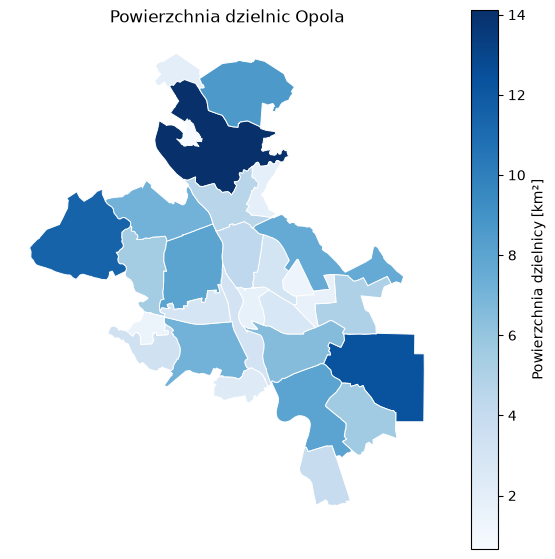

In [18]:
import matplotlib.pyplot as plt

ax = districts.plot(
    column="area_km2",
    cmap="Blues",
    legend=True,
    legend_kwds={"label": "Powierzchnia dzielnicy [km²]"},
    edgecolor="white",
    linewidth=0.7,
    figsize=(7, 7),
)

ax.set_title("Powierzchnia dzielnic Opola")
ax.set_axis_off()
plt.show()

### część A7 ###

In [19]:
joined = gpd.sjoin(
    sensors_m,
    districts[["name", "geometry"]],
    how="left",
    predicate="within",
)

print("Liczba wierszy po połączeniu:", len(joined))
print("Odczyty bez przypisanej dzielnicy:", joined["name"].isna().sum())
display(joined[["sensor_id", "pm25", "name"]].head())

Liczba wierszy po połączeniu: 130
Odczyty bez przypisanej dzielnicy: 0


,sensor_id,pm25,name
0,PM-042,23.5,Nadodrze
1,PM-106,12.4,Winów
2,PM-130,19.4,Grudzice
3,PM-025,16.8,Chabry
4,PM-137,14.4,Półwieś


In [20]:
stats = (
    joined.groupby("name")
    .agg(
        pm25_mean=("pm25", "mean"),
        sensor_count=("pm25", "size"),
    )
)

summary = districts.merge(stats, on="name", how="left")
print("Dzielnice bez odczytów:", summary["sensor_count"].isna().sum())

reliable = summary[summary["sensor_count"] >= 3]
top3 = reliable.nlargest(3, "pm25_mean")
display(top3[["name", "pm25_mean", "sensor_count"]].round(1))

Dzielnice bez odczytów: 3


,name,pm25_mean,sensor_count
18,Stare Miasto,29.6,3.0
26,Śródmieście,26.8,7.0
25,Zaodrze,22.5,6.0


In [21]:
summary.explore(
    column="pm25_mean",
    cmap="Oranges",
    scheme="quantiles",
    k=5,
    tooltip=["name", "pm25_mean", "sensor_count"],
    tooltip_kwds={"aliases": ["Dzielnica", "Średnie PM2.5 [µg/m³]", "Liczba odczytów"]},
    legend_kwds={"caption": "Średnie PM2.5 [µg/m³]"},
    missing_kwds={"color": "lightgray", "label": "Brak odczytów"},
)

### część A8 ### 

In [22]:
schools = gpd.read_file("dane/opole_schools.geojson").to_crs("EPSG:2180")

buffers = schools.copy()
buffers["geometry"] = schools.geometry.buffer(500)

print("Liczba szkół:", len(schools))
display(buffers[["name", "geometry"]].head())

Liczba szkół: 19


,name,geometry
0,Niepubliczna Szkoła Podstawowa Nasza Szkoła,"POLYGON ((425250.442 313309.464, 425248.034 31..."
1,Publiczna Szkoła Podstawowa nr 1 im. Obrońców ...,"POLYGON ((424964.042 311369.771, 424961.635 31..."
2,Publiczna Szkoła Podstawowa nr 10 im. Henryka ...,"POLYGON ((422845.594 310511.192, 422843.186 31..."
3,Publiczna Szkoła Podstawowa nr 11 im. Orląt Lw...,"POLYGON ((424776.746 313105.386, 424774.339 31..."
4,Publiczna Szkoła Podstawowa nr 15,"POLYGON ((426715.075 312203.008, 426712.668 31..."


In [23]:
near_schools = gpd.sjoin(
    sensors_m,
    buffers[["name", "geometry"]],
    how="inner",
    predicate="within",
)

print("Szkoły z co najmniej jednym odczytem w promieniu 500 m:",
      near_schools["index_right"].nunique())
print(f"Średnie PM2.5 przy szkołach: {near_schools['pm25'].mean():.1f} µg/m³")

city = districts.geometry.union_all()
school_zone = buffers.geometry.union_all()
coverage = school_zone.intersection(city).area / city.area

print(f"Część powierzchni miasta w promieniu 500 m od szkoły: {coverage:.1%}")

Szkoły z co najmniej jednym odczytem w promieniu 500 m: 11
Średnie PM2.5 przy szkołach: 22.3 µg/m³
Część powierzchni miasta w promieniu 500 m od szkoły: 9.5%


In [24]:
m = districts.explore(
    color="gray",
    style_kwds={"fillOpacity": 0.05},
    name="Dzielnice",
)

buffers.explore(
    m=m,
    color="orange",
    style_kwds={"fillOpacity": 0.25},
    tooltip=["name"],
    name="Obszary 500 m od szkół",
)

sensors_m.explore(
    m=m,
    color="black",
    marker_kwds={"radius": 3},
    tooltip=["sensor_id", "pm25"],
    name="Czujniki PM2.5",
)

m

### część A9 ###

In [25]:
from pathlib import Path

out = Path("wyniki")
out.mkdir(exist_ok=True)

gpkg = out / "pm25.gpkg"

summary.to_file(gpkg, layer="districts", driver="GPKG", index=False)
sensors_m.to_file(gpkg, layer="sensors", driver="GPKG", index=False)

summary.to_crs("EPSG:4326").to_file(
    out / "pm25_districts.geojson",
    driver="GeoJSON",
    index=False,
)

print("Folder z wynikami:", out.resolve())
display(gpd.list_layers(gpkg))

Folder z wynikami: C:\Users\dawid\Desktop\lab_geo\wyniki


,name,geometry_type
0,districts,Polygon
1,sensors,Point


In [26]:
dzielnice_z_pliku = gpd.read_file(gpkg, layer="districts")
czujniki_z_pliku = gpd.read_file(gpkg, layer="sensors")
dzielnice_geojson = gpd.read_file(out / "pm25_districts.geojson")

print("GPKG — dzielnice:", len(dzielnice_z_pliku), "|", dzielnice_z_pliku.crs)
print("GPKG — czujniki:", len(czujniki_z_pliku), "|", czujniki_z_pliku.crs)
print("GeoJSON — dzielnice:", len(dzielnice_geojson), "|", dzielnice_geojson.crs)

display(dzielnice_z_pliku[["name", "pm25_mean", "sensor_count"]].head())

GPKG — dzielnice: 29 | EPSG:2180
GPKG — czujniki: 130 | EPSG:2180
GeoJSON — dzielnice: 29 | EPSG:4326


,name,pm25_mean,sensor_count
0,Armii Krajowej,19.100000,1.0
1,Bierkowice,NaN,NaN
2,Borki,NaN,NaN
3,Brzezie,16.100000,3.0
4,Chabry,20.416667,6.0
